# NLP Lab 1 - Transformers (ParaDetox)

In [1]:
!pip -q install datasets gensim transformers accelerate scikit-learn

## Setup: load data + tokenize
Each row of ParaDetox is a pair: a toxic sentence and its neutral rewrite.

In [2]:
import re
from collections import Counter
import pandas as pd
import numpy as np

df = pd.read_csv("paradetox.txt", sep="\t")
print(df)

                                                 Style 1  \
0                               he had steel balls too !   
1      dude should have been taken to api , he would ...   
2      im not gonna sell the fucking picture , i just...   
3      the garbage that is being created by cnn and o...   
4      the reason they dont exist is because neither ...   
...                                                  ...   
12515  both sides need to calm the fuck down or we ar...   
12516  i 'm sitting here in my calm german city conte...   
12517                        dude , get a fucking clue .   
12518            i was so fuckin high , it was amazing .   
12519                      tough shit , pay your bills .   

                                                 Style 2  
0                                      he was brave too!  
1      It would have been good if he went to api. He ...  
2      I'm not gonna sell the picture, i just want to...  
3      the news that is being created by cn

In [4]:
toxic, neutral = [], []
with open("paradetox.txt", encoding="utf-8") as f:
  next(f)
  for line in f:
    parts = line.split("\t")
    if len(parts) == 2 and parts[0].strip() and parts[1].strip():
      toxic.append(parts[0].strip())
      neutral.append(parts[1].strip())
df = pd.DataFrame({"toxic": toxic, "neutral": neutral})
print(df)

                                                   toxic  \
0                               he had steel balls too !   
1      dude should have been taken to api , he would ...   
2      im not gonna sell the fucking picture , i just...   
3      the garbage that is being created by cnn and o...   
4      the reason they dont exist is because neither ...   
...                                                  ...   
12515  both sides need to calm the fuck down or we ar...   
12516  i 'm sitting here in my calm german city conte...   
12517                        dude , get a fucking clue .   
12518            i was so fuckin high , it was amazing .   
12519                      tough shit , pay your bills .   

                                                 neutral  
0                                      he was brave too!  
1      It would have been good if he went to api. He ...  
2      I'm not gonna sell the picture, i just want to...  
3      the news that is being created by cn

In [11]:
def tok(s):
    return re.findall(r"[a-z0-9']+", s.lower())
toxic_tok = [tok(s) for s in toxic]
neutral_tok = [tok(s) for s in neutral]
print(toxic_tok)
print(neutral_tok)

[['he', 'had', 'steel', 'balls', 'too'], ['dude', 'should', 'have', 'been', 'taken', 'to', 'api', 'he', 'would', 'be', 'right', 'at', 'home', 'with', 'all', 'the', 'other', 'knuckleheads', 'there'], ['im', 'not', 'gonna', 'sell', 'the', 'fucking', 'picture', 'i', 'just', 'want', 'to', 'contribute', 'to', 'the', 'fucking', 'article'], ['the', 'garbage', 'that', 'is', 'being', 'created', 'by', 'cnn', 'and', 'other', 'news', 'agencies', 'is', 'outrageous'], ['the', 'reason', 'they', 'dont', 'exist', 'is', 'because', 'neither', 'is', 'a', 'pathological', 'liar', 'like', 'trump'], ['i', 'hope', 'they', 'beat', 'each', 'other', 'silly'], ['no', 'good', 'bastards', 'that', 'we', 'are', 'and', 'we', 'are', 'unrepentant', 'about', 'it'], ['stop', 'the', 'coverage', 'and', 'let', 'em', 'rot'], ['delete', 'the', 'page', 'and', 'shut', 'up'], ['every', 'time', 'you', 'flag', 'the', 'post', 'like', 'a', 'coward', 'you', 'make', 'my', 'point'], ['only', 'to', 'replaced', 'by', 'another', 'braindead'

## Task 1: word counts per class


In [12]:
c_toxic = Counter(w for s in toxic_tok for w in s)
c_neutral = Counter(w for s in neutral_tok for w in s)

vocab = sorted(set(c_toxic) | set(c_neutral))

counts = pd.DataFrame({
    "word": vocab,
    "toxic": [c_toxic.get(w, 0) for w in vocab],
    "neutral": [c_neutral.get(w, 0) for w in vocab]
})

counts.sort_values("toxic", ascending=False).head(20)



,word,toxic,neutral
10257,the,4387,3317
9143,shit,3806,4
5010,i,3341,3181
194,a,2962,2148
10431,to,2706,2680
11692,you,2679,2694
5415,is,2141,2319
10247,that,2125,1878
4060,fuck,2112,0
529,and,1982,1659


In [13]:
# a little optimization
counts["diff"] = counts.toxic - counts.neutral
counts.sort_values("diff", ascending=False).head(20)

,word,toxic,neutral,diff
9143,shit,3806,4,3802
4060,fuck,2112,0,2112
4076,fucking,1739,0,1739
10257,the,4387,3317,1070
725,ass,973,0,973
42,'t,1202,369,833
194,a,2962,2148,814
38,'s,935,279,656
1202,bitch,567,0,567
4066,fucked,333,0,333


## Task 2: Word2Vec CBOW, context size 3

In [14]:
from gensim.models import Word2Vec

all_sentences = toxic_tok + neutral_tok
w2v = Word2Vec(
    sentences=all_sentences,
    vector_size=100,
    window=3,
    sg=0,
    min_count=1,
    workers=2,
    epochs=20,
    seed=42,
)
print(len(w2v.wv), "words in vocabulary")

11752 words in vocabulary


In [22]:
w2v.wv["shit"]

array([-8.8000727e-01,  2.1015063e-01, -9.3849826e-01, -7.3976403e-01,
       -7.4016392e-01,  5.6037724e-01,  3.3510378e-01, -6.4061552e-01,
       -4.4878516e-01, -7.7092624e-01,  7.0121408e-01,  5.9646899e-01,
        3.4034088e-01,  1.2806059e+00,  1.7095484e+00,  4.0899020e-01,
        1.0002043e+00, -2.1712947e-01, -1.0880885e+00, -2.4189179e-01,
       -1.7744995e+00,  1.8726323e+00,  8.2250851e-01, -1.0967172e+00,
        2.4512036e+00, -9.9300283e-01, -1.6096430e-02, -7.9213959e-01,
        8.6514187e-01,  1.6469575e-01, -2.4503993e-02, -2.0964423e-01,
        9.5929945e-01,  1.3421718e+00,  1.2661014e-01,  2.0765929e+00,
        1.3193952e-01, -1.6700870e+00, -8.0548991e-05, -1.4358568e-01,
        2.6574451e-01,  1.5276248e+00, -6.2593651e-01, -9.8581046e-01,
       -7.5477141e-01,  3.2215688e-01,  2.3440741e-01,  4.8622480e-01,
       -2.0020656e-01, -9.8707825e-01,  1.2390488e+00, -1.5308080e+00,
       -1.7583818e+00,  9.2592025e-01, -1.1669205e-01,  3.7321761e-01,
      

In [23]:
w2v.wv.most_similar("shit")

[('crap', 0.7180241346359253),
 ('stuff', 0.7085358500480652),
 ('thing', 0.6488962173461914),
 ('things', 0.6148102283477783),
 ('fuck', 0.572353184223175),
 ('infant', 0.51168292760849),
 ('shittt', 0.5089835524559021),
 ('girl', 0.4968872666358948),
 ('shits', 0.4790188670158386),
 ('game', 0.47215887904167175)]

## Task 3: visualize first 15 words of each class


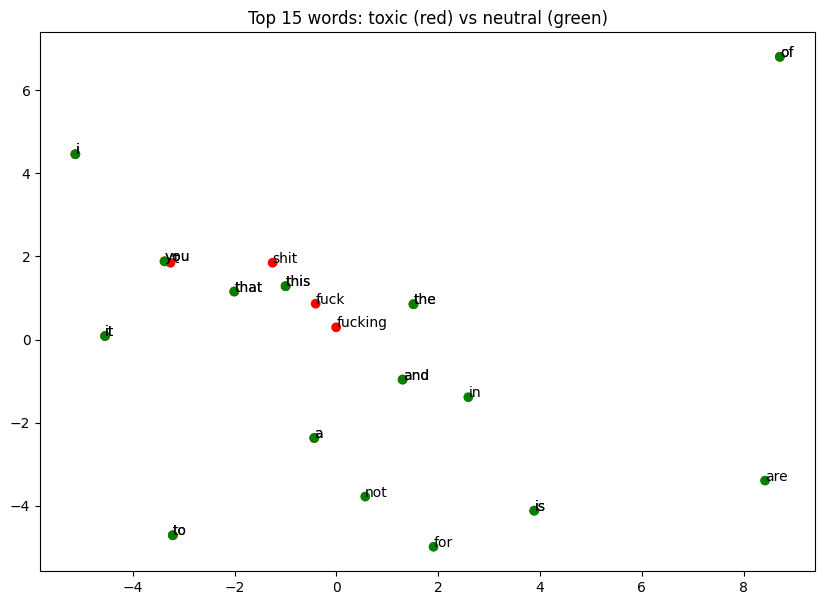

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

top_toxic = [w for w, _ in c_toxic.most_common(15)]
top_neutral = [w for w, _ in c_neutral.most_common(15)]
words = top_toxic + top_neutral

colors = ["red"] * 15 + ["green"] * 15

pts = PCA(n_components=2).fit_transform(np.array([w2v.wv[w] for w in words]))

plt.figure(figsize=(10, 7))
plt.scatter(pts[:, 0], pts[:, 1], c=colors)
for (x, y), w in zip(pts, words):
    plt.annotate(w, (x, y), fontsize=10)

plt.title("Top 15 words: toxic (red) vs neutral (green)")
plt.show()

## Task 4: sentence vector = max per dimension over its word vectors

In [27]:
def sent_vec(tokens):
    vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
    return np.max(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

X_toxic   = np.array([sent_vec(s) for s in toxic_tok])
X_neutral = np.array([sent_vec(s) for s in neutral_tok])
print(X_toxic.shape, X_neutral.shape)

(12520, 100) (12520, 100)


## Task 5: split 90 / 5 / 5

In [29]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(df))
train_idx, tmp_idx  = train_test_split(idx, test_size=0.10, random_state=13)
val_idx,   test_idx = train_test_split(tmp_idx, test_size=0.50, random_state=13)

def build(ix):
    texts  = [toxic[i] for i in ix] + [neutral[i] for i in ix]
    labels = [1] * len(ix) + [0] * len(ix)
    X      = np.vstack([X_toxic[ix], X_neutral[ix]])
    return texts, labels, X

train_texts, train_labels, X_train = build(train_idx)
val_texts,   val_labels,   X_val   = build(val_idx)
test_texts,  test_labels,  X_test  = build(test_idx)

print(len(train_texts), len(val_texts), len(test_texts))

22536 1252 1252


## Task 6: fine-tune BERT for toxic / not toxic
BERT is already "well-read"; we only give it a short course on this specific task (fine-tuning).

In [30]:
import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

MODEL = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL)

def make_ds(texts, labels):
    d = Dataset.from_dict({"text": texts, "label": labels})
    d = d.map(lambda b: tokenizer(b["text"], truncation=True, max_length=64), batched=True)
    return d.remove_columns(["text"])

train_ds = make_ds(train_texts, train_labels)
val_ds   = make_ds(val_texts,   val_labels)
test_ds  = make_ds(test_texts,  test_labels)

model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary")
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1}

args = TrainingArguments(
    output_dir="bert_out",
    num_train_epochs=2,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=torch.cuda.is_available(),
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/22536 [00:00<?, ? examples/s]

Map:   0%|          | 0/1252 [00:00<?, ? examples/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=1410, training_loss=0.08393222592401166, metrics={'train_runtime': 139.776, 'train_samples_per_second': 322.459, 'train_steps_per_second': 10.088, 'total_flos': 573092878566240.0, 'train_loss': 0.08393222592401166, 'epoch': 2.0})

In [31]:
results = trainer.evaluate(test_ds)
print(results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.058016,0.068088,2,0.978435,0.970173,0.987220,0.978622


{'eval_loss': 0.06808791309595108, 'eval_accuracy': 0.9784345047923323, 'eval_precision': 0.9701726844583988, 'eval_recall': 0.987220447284345, 'eval_f1': 0.9786223277909739}
